In [2]:
import collections

class Graph:
    def __init__(self, directed=False):
        self.graph = collections.defaultdict(list)
        self.directed = directed
        
    def add_edge(self, u, v):
        self.graph[u].append(v)
        if not self.directed:
            self.graph[v].append(u) # Untuk graph tak berarah, tambahkan juga edge dari v ke u

    def get_neighbors(self, u):
        return self.graph[u]
        
    def display(self):
        print("Adjacency List:")
        for node in sorted(self.graph.keys()):
            print(f"{node}: {self.graph[node]}")
            
# Membuat dan menampilkan graph tak berarah
print("Graph Tak Berarah:")
undirected_graph = Graph(directed=False)
undirected_graph.add_edge('A', 'B')
undirected_graph.add_edge('A', 'C')
undirected_graph.add_edge('B', 'D')
undirected_graph.add_edge('C', 'E')
undirected_graph.add_edge('D', 'E')
undirected_graph.display()

print("\nGraph Berarah:")
# Membuat dan menampilkan graph berarah
directed_graph = Graph(directed=True)
directed_graph.add_edge('0', '1')
directed_graph.add_edge('0', '2')
directed_graph.add_edge('1', '2')
directed_graph.add_edge('2', '0')
directed_graph.add_edge('2', '3')
directed_graph.add_edge('3', '3')
directed_graph.display()

Graph Tak Berarah:
Adjacency List:
A: ['B', 'C']
B: ['A', 'D']
C: ['A', 'E']
D: ['B', 'E']
E: ['C', 'D']

Graph Berarah:
Adjacency List:
0: ['1', '2']
1: ['2']
2: ['0', '3']
3: ['3']


In [4]:
import collections

class AdjacencyMatrixGraph:
    def __init__(self, num_vertices, directed=False):
        self.num_vertices = num_vertices
        self.directed = directed
        # Inisialisasi matriks dengan semua nilai 0
        self.matrix = [[0] * num_vertices for _ in range(num_vertices)]
        self.vertex_map = {}
        self.reverse_vertex_map = []
        self.next_vertex_id = 0
        
    def _get_vertex_index(self, vertex_label):
        if vertex_label not in self.vertex_map:
            self.vertex_map[vertex_label] = self.next_vertex_id
            self.reverse_vertex_map.append(vertex_label)
            self.next_vertex_id += 1
        return self.vertex_map[vertex_label]
        
    def add_edge(self, u, v, weight=1):
        u_idx = self._get_vertex_index(u)
        v_idx = self._get_vertex_index(v)
        
        if u_idx >= self.num_vertices or v_idx >= self.num_vertices:
            print("Error: Vertex index out of bounds. Increase num_vertices or choose existing one")
            return
            
        self.matrix[u_idx][v_idx] = weight
        if not self.directed:
            self.matrix[v_idx][u_idx] = weight
            
    def display(self):
        print("Adjacency Matrix:")
        # Print header row
        header = [str(label) for label in self.reverse_vertex_map]
        print(" " + " ".join(header))
        for i, row in enumerate(self.matrix):
            if i < len(self.reverse_vertex_map):
                print(f"{self.reverse_vertex_map[i]} {' '.join(map(str, row))}")
            else:
                print(f"? {' '.join(map(str, row))}") # For unmapped vertices if any

# Membuat dan menampilkan graph tak berarah menggunakan Adjacency Matrix
print("Graph Tak Berarah (Adjacency Matrix):")
# Kita asumsikan ada 5 verteks (A, B, C, D, E)
undirected_adj_matrix = AdjacencyMatrixGraph(num_vertices=5, directed=False)
undirected_adj_matrix.add_edge('A', 'B')
undirected_adj_matrix.add_edge('A', 'C')
undirected_adj_matrix.add_edge('B', 'D')
undirected_adj_matrix.add_edge('C', 'E')
undirected_adj_matrix.add_edge('D', 'E')
undirected_adj_matrix.display()

print("\nGraph Berarah (Adjacency Matrix):")
# Kita asumsikan ada 4 verteks (0, 1, 2, 3)
directed_adj_matrix = AdjacencyMatrixGraph(num_vertices=4, directed=True)
directed_adj_matrix.add_edge('0', '1')
directed_adj_matrix.add_edge('0', '2')
directed_adj_matrix.add_edge('1', '2')
directed_adj_matrix.add_edge('2', '0')
directed_adj_matrix.add_edge('2', '3')
directed_adj_matrix.add_edge('3', '3')
directed_adj_matrix.display()

Graph Tak Berarah (Adjacency Matrix):
Adjacency Matrix:
 A B C D E
A 0 1 1 0 0
B 1 0 0 1 0
C 1 0 0 0 1
D 0 1 0 0 1
E 0 0 1 1 0

Graph Berarah (Adjacency Matrix):
Adjacency Matrix:
 0 1 2 3
0 0 1 1 0
1 0 0 1 0
2 1 0 0 1
3 0 0 0 1


In [5]:
import collections

def bfs(graph_obj, start_node):
    # Set untuk menyimpan node yang sudah dikunjungi
    visited = set()
    # Queue untuk BFS
    queue = collections.deque([start_node])
    # List untuk menyimpan urutan penjelajahan
    traversal_order = []
    
    visited.add(start_node)
    
    while queue:
        current_node = queue.popleft()
        traversal_order.append(current_node)
        
        # Jelajahi semua tetangga dari node saat ini
        for neighbor in graph_obj.get_neighbors(current_node):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)
                
    return traversal_order

# Gunakan graph tak berarah yang sudah dibuat sebelumnya
print("BFS Traversal (Graph Tak Berarah dari A):")
bfs_result_undirected = bfs(undirected_graph, 'A')
print(bfs_result_undirected)

# Gunakan graph berarah yang sudah dibuat sebelumnya
print("\nBFS Traversal (Graph Berarah dari 2):")
bfs_result_directed = bfs(directed_graph, '2')
print(bfs_result_directed)

BFS Traversal (Graph Tak Berarah dari A):
['A', 'B', 'C', 'D', 'E']

BFS Traversal (Graph Berarah dari 2):
['2', '0', '3', '1']


In [6]:
def dfs(graph_obj, start_node):
    # Set untuk menyimpan node yang sudah dikunjungi
    visited = set()
    # Stack untuk DFS (menggunakan list sebagai stack, pop() untuk mengambil elemen terakhir)
    stack = [start_node]
    # List untuk menyimpan urutan penjelajahan
    traversal_order = []
    
    while stack:
        current_node = stack.pop()
        
        if current_node not in visited:
            visited.add(current_node)
            traversal_order.append(current_node)
            
            # Jelajahi semua tetangga dari node saat ini
            # Penting: untuk konsistensi, kita reverse tetangga agar node dengan "nilai" lebih kecil diproses terlebih dahulu
            # diproses terlebih dahulu jika menggunakan pop() dari stack (LIFO)
            # atau cukup ambil sesuai urutan untuk visualisasi yang lebih intuitif.
            # Di sini, kita akan menambahkan tetangga ke stack dalam urutan terbalik
            # agar node dengan label 'lebih kecil' (berdasarkan sorting) dieksplorasi duluan
            # jika kita pop dari stack.
            # Atau, jika tidak ingin sorting, cukup tambahkan: for neighbor in graph_obj.get_neig
            for neighbor in sorted(graph_obj.get_neighbors(current_node), reverse=True):
                if neighbor not in visited:
                    stack.append(neighbor)       
    return traversal_order

# Gunakan graph tak berarah yang sudah dibuat sebelumnya
print("DFS Traversal (Graph Tak Berarah dari A):")
dfs_result_undirected = dfs(undirected_graph, 'A')
print(dfs_result_undirected)

# Gunakan graph berarah yang sudah dibuat sebelumnya
print("\nDFS Traversal (Graph Berarah dari 2):")
dfs_result_directed = dfs(directed_graph, '2')
print(dfs_result_directed)

DFS Traversal (Graph Tak Berarah dari A):
['A', 'B', 'D', 'E', 'C']

DFS Traversal (Graph Berarah dari 2):
['2', '0', '1', '3']


In [7]:
import graphviz

# Function to visualize Graph (Adjacency List)
def visualize_adjacency_list(graph_obj, graph_name="Graph", highlight_path=None):
    """
    Visualizes a graph represented by an adjacency list using Graphviz.

    Args:
        graph_obj (Graph): The graph object (Adjacency List).
        graph_name (str): The name for the graph visualization.
        highlight_path (list): An optional list of nodes to highlight as a path.
    """
    dot = graphviz.Digraph(comment=graph_name) if graph_obj.directed else graphviz.Graph(comment=graph_name)
    dot.attr(rankdir='LR') # Left to Right layout

    nodes_in_graph = set()
    for u, neighbors in graph_obj.graph.items():
        nodes_in_graph.add(str(u))
        for v in neighbors:
            nodes_in_graph.add(str(v))

    # Add all nodes first
    for node in sorted(list(nodes_in_graph)):
        dot.node(node, style='filled', fillcolor='lightblue')

    # Add edges
    added_edges = set() # To avoid duplicate edges for undirected graph
    for u, neighbors in graph_obj.graph.items():
        for v in neighbors:
            # For undirected graphs, add edge only once (e.g., A-B, not B-A again)
            if not graph_obj.directed:
                # Check if the reverse edge was already added
                if (str(v), str(u)) in added_edges or (str(u), str(v)) in added_edges:
                    continue
            dot.edge(str(u), str(v))
            added_edges.add((str(u), str(v))) # Store the edge as (source, dest)

    # Highlight path if provided
    if highlight_path:
        for i in range(len(highlight_path)):
            node = str(highlight_path[i])
            # Highlight start node in red, other path nodes in lightgreen
            dot.node(node, style='filled', fillcolor='red' if i == 0 else 'lightgreen', fontcolor='black')

            if i < len(highlight_path) - 1:
                u = str(highlight_path[i])
                v = str(highlight_path[i+1])
                # Highlight path edges in red with thicker penwidth
                dot.edge(u, v, color='red', penwidth='2.0')

    return dot

# Function to visualize Adjacency Matrix
def visualize_adjacency_matrix(adj_matrix_obj, graph_name="Graph", highlight_path=None):
    """
    Visualizes a graph represented by an adjacency matrix using Graphviz.

    Args:
        adj_matrix_obj (AdjacencyMatrixGraph): The graph object (Adjacency Matrix).
        graph_name (str): The name for the graph visualization.
        highlight_path (list): An optional list of nodes to highlight as a path.
    """
    dot = graphviz.Digraph(comment=graph_name) if adj_matrix_obj.directed else graphviz.Graph(comment=graph_name)
    dot.attr(rankdir='LR')

    num_vertices = adj_matrix_obj.num_vertices
    # Map vertex indices back to their original labels for visualization
    vertex_labels = [adj_matrix_obj.reverse_vertex_map[i] if i < len(adj_matrix_obj.reverse_vertex_map) else f"?{i}" for i in range(num_vertices)]

    # Add all nodes
    for label in vertex_labels:
        dot.node(str(label), style='filled', fillcolor='lightblue')

    # Add edges
    added_edges = set()
    for i in range(num_vertices):
        for j in range(num_vertices):
            if adj_matrix_obj.matrix[i][j] != 0:
                u_label = str(vertex_labels[i])
                v_label = str(vertex_labels[j])
                weight = adj_matrix_obj.matrix[i][j]

                if not adj_matrix_obj.directed:
                    # For undirected, add edge only once (e.g., A-B, not B-A again)
                    if (v_label, u_label) in added_edges or (u_label, v_label) in added_edges:
                        continue

                dot.edge(u_label, v_label, label=str(weight) if weight != 1 else '')
                added_edges.add((u_label, v_label))

    # Highlight path if provided
    if highlight_path:
        for i in range(len(highlight_path)):
            node = str(highlight_path[i])
            # Highlight start node in red, other path nodes in lightgreen
            dot.node(node, style='filled', fillcolor='red' if i == 0 else 'lightgreen', fontcolor='black')

            if i < len(highlight_path) - 1:
                u = str(highlight_path[i])
                v = str(highlight_path[i+1])
                # Highlight path edges in red with thicker penwidth
                dot.edge(u, v, color='red', penwidth='2.0')

    return dot

# --- Visualisasi Graph Adjacency List ---
print("### Visualisasi Graph Menggunakan Adjacency List\n")

print("#### Graph Tak Berarah (Adjacency List):\n")
# display(visualize_adjacency_list(undirected_graph, graph_name="Undirected Graph (Adjacency List)"))

print("\n#### Graph Berarah (Adjacency List):\n")
# display(visualize_adjacency_list(directed_graph, graph_name="Directed Graph (Adjacency List)"))

print("\n### Visualisasi Traversal (BFS) untuk Adjacency List\n")

print("#### BFS Traversal (Graph Tak Berarah dari A):\n")
# display(visualize_adjacency_list(undirected_graph, graph_name="BFS Undirected from A", highlight_path=bfs_result_undirected))

print("\n#### BFS Traversal (Graph Berarah dari 2):\n")
# display(visualize_adjacency_list(directed_graph, graph_name="BFS Directed from 2", highlight_path=bfs_result_directed))

print("\n### Visualisasi Traversal (DFS) untuk Adjacency List\n")

print("#### DFS Traversal (Graph Tak Berarah dari A):\n")
# display(visualize_adjacency_list(undirected_graph, graph_name="DFS Undirected from A", highlight_path=dfs_result_undirected))

print("\n#### DFS Traversal (Graph Berarah dari 2):\n")
# display(visualize_adjacency_list(directed_graph, graph_name="DFS Directed from 2", highlight_path=dfs_result_directed))


# --- Visualisasi Graph Adjacency Matrix ---
print("\n### Visualisasi Graph Menggunakan Adjacency Matrix\n")

print("#### Graph Tak Berarah (Adjacency Matrix):\n")
# display(visualize_adjacency_matrix(undirected_adj_matrix, graph_name="Undirected Graph (Adjacency Matrix)"))

print("\n#### Graph Berarah (Adjacency Matrix):\n")
# display(visualize_adjacency_matrix(directed_adj_matrix, graph_name="Directed Graph (Adjacency Matrix)"))

print("\n### Visualisasi Traversal (BFS) untuk Adjacency Matrix\n")

# Note: BFS/DFS functions were written for Adjacency List graph_obj.get_neighbors()
# We reuse the traversal results derived from the Adjacency List graphs for visualization
# assuming the graph structure for matrix is analogous.
print("#### BFS Traversal (Graph Tak Berarah dari A - Matriks):\n")
# display(visualize_adjacency_matrix(undirected_adj_matrix, graph_name="BFS Undirected Matrix from A", highlight_path=bfs_result_undirected))

print("\n#### BFS Traversal (Graph Berarah dari 2 - Matriks):\n")
# display(visualize_adjacency_matrix(directed_adj_matrix, graph_name="BFS Directed Matrix from 2", highlight_path=bfs_result_directed))

print("\n### Visualisasi Traversal (DFS) untuk Adjacency Matrix\n")

print("#### DFS Traversal (Graph Tak Berarah dari A - Matriks):\n")
# display(visualize_adjacency_matrix(undirected_adj_matrix, graph_name="DFS Undirected Matrix from A", highlight_path=dfs_result_undirected))

print("\n#### DFS Traversal (Graph Berarah dari 2 - Matriks):\n")
# display(visualize_adjacency_matrix(directed_adj_matrix, graph_name="DFS Directed Matrix from 2", highlight_path=dfs_result_directed))

### Visualisasi Graph Menggunakan Adjacency List

#### Graph Tak Berarah (Adjacency List):


#### Graph Berarah (Adjacency List):


### Visualisasi Traversal (BFS) untuk Adjacency List

#### BFS Traversal (Graph Tak Berarah dari A):


#### BFS Traversal (Graph Berarah dari 2):


### Visualisasi Traversal (DFS) untuk Adjacency List

#### DFS Traversal (Graph Tak Berarah dari A):


#### DFS Traversal (Graph Berarah dari 2):


### Visualisasi Graph Menggunakan Adjacency Matrix

#### Graph Tak Berarah (Adjacency Matrix):


#### Graph Berarah (Adjacency Matrix):


### Visualisasi Traversal (BFS) untuk Adjacency Matrix

#### BFS Traversal (Graph Tak Berarah dari A - Matriks):


#### BFS Traversal (Graph Berarah dari 2 - Matriks):


### Visualisasi Traversal (DFS) untuk Adjacency Matrix

#### DFS Traversal (Graph Tak Berarah dari A - Matriks):


#### DFS Traversal (Graph Berarah dari 2 - Matriks):



In [8]:
import heapq
import collections

class WeightedGraph:
    def __init__(self):
        # Graph disimpan sebagai adjacency list, dengan setiap edge memiliki bobot
        # self.graph[u] = [(v, weight), (v2, weight2), ...]
        self.graph = collections.defaultdict(list)
        self.nodes = set() # Set untuk menyimpan semua node unik dalam graph
        
    def add_edge(self, u, v, weight):
        # Tambahkan edge dari u ke v dengan bobot
        self.graph[u].append((v, weight))
        self.nodes.add(u) # Tambahkan u ke set node
        self.nodes.add(v) # Tambahkan v ke set node
        
    def dijkstra(self, start_node):
        # Dictionary untuk menyimpan jarak terpendek dari start_node ke setiap node
        # Inisialisasi dengan semua node yang diketahui
        distances = {node: float('infinity') for node in self.nodes}
        distances[start_node] = 0
        
        # Priority queue untuk menyimpan (jarak, node)
        # heapq akan memastikan node dengan jarak terpendek selalu berada di awal
        priority_queue = [(0, start_node)]
        
        # Dictionary untuk menyimpan jalur terpendek (previous node dalam jalur)
        previous_nodes = {}
        
        while priority_queue:
            current_distance, current_node = heapq.heappop(priority_queue)
            
            # Jika jarak yang diambil dari queue lebih besar dari jarak yang sudah diketahui,
            # berarti kita sudah menemukan jalur yang lebih pendek sebelumnya, jadi abaikan.
            if current_distance > distances[current_node]:
                continue
                
            # Jelajahi setiap tetangga dari current_node
            for neighbor, weight in self.graph[current_node]:
                distance = current_distance + weight
                
                # Jika jarak baru lebih pendek dari jarak yang sudah diketahui ke tetangga
                if distance < distances[neighbor]:
                    distances[neighbor] = distance
                    previous_nodes[neighbor] = current_node
                    heapq.heappush(priority_queue, (distance, neighbor))
                    
        return distances, previous_nodes
        
    def get_shortest_path(self, start_node, end_node, previous_nodes):
        path = collections.deque()
        current = end_node
        while current is not None:
            path.appendleft(current)
            current = previous_nodes.get(current)
            if current == start_node:
                path.appendleft(current)
                break
                
            # If current node is not start_node and not in previous_nodes, there is no path
            if current is not None and current not in previous_nodes and current != start_node:
                return [] # No path found
                
        # Check if start_node is the first element of the path
        if path and path[0] == start_node:
            return list(path)
        else:
            return [] # No path found or start_node is not in path

# Membuat instance WeightedGraph
weighted_graph = WeightedGraph()

# Menambahkan edge dengan bobot
weighted_graph.add_edge('A', 'B', 4)
weighted_graph.add_edge('A', 'C', 2)
weighted_graph.add_edge('B', 'E', 3)
weighted_graph.add_edge('C', 'D', 2)
weighted_graph.add_edge('C', 'F', 4)
weighted_graph.add_edge('D', 'E', 3)
weighted_graph.add_edge('D', 'F', 1)
weighted_graph.add_edge('E', 'G', 2)
weighted_graph.add_edge('F', 'G', 1)

start_node_dijkstra = 'A'

# Menjalankan algoritma Dijkstra
distances, previous_nodes = weighted_graph.dijkstra(start_node_dijkstra)

print(f"Jarak terpendek dari node '{start_node_dijkstra}':")
for node, dist in distances.items():
    print(f"  Ke {node}: {dist}")

print(f"\nJalur terpendek dari node '{start_node_dijkstra}':")
for node in weighted_graph.nodes: # Iterate through all unique nodes
    if node != start_node_dijkstra:
        path = weighted_graph.get_shortest_path(start_node_dijkstra, node, previous_nodes)
        if path:
            print(f"  Ke {node}: {' -> '.join(path)}")
        else:
            print(f"  Ke {node}: Tidak ada jalur")

Jarak terpendek dari node 'A':
  Ke D: 4
  Ke G: 6
  Ke E: 7
  Ke A: 0
  Ke F: 5
  Ke B: 4
  Ke C: 2

Jalur terpendek dari node 'A':
  Ke D: A -> C -> D
  Ke G: A -> C -> D -> F -> G
  Ke E: A -> B -> E
  Ke F: A -> C -> D -> F
  Ke B: A -> B
  Ke C: A -> C


#TUGAS

Visualisasi Graph Sesuai Urutan Peta Jawa Tengah:


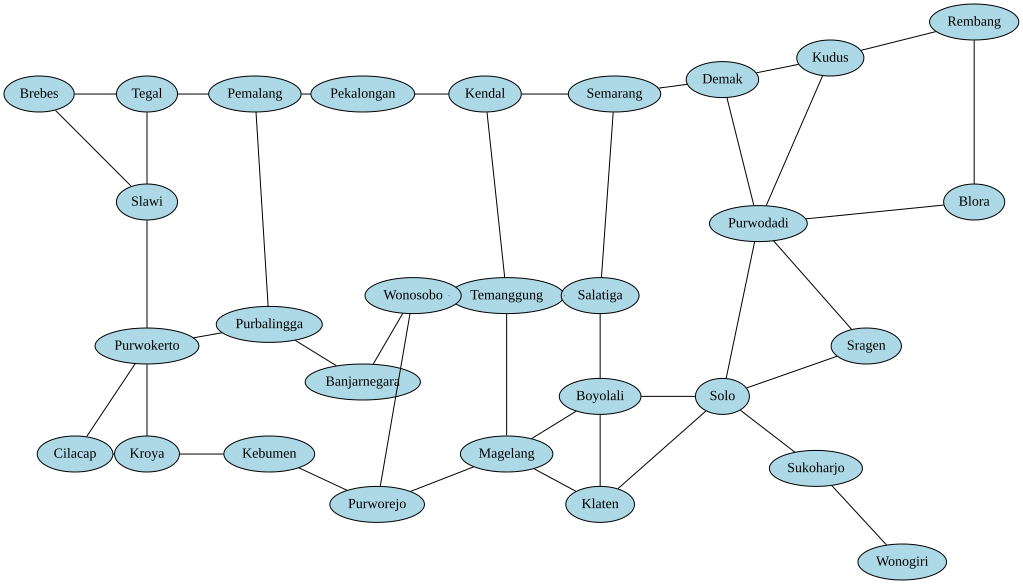

In [1]:
import collections
import graphviz
from IPython.display import display

# 1. Definisi Kelas Graph (Sesuai sumber [2])
class Graph:
    def __init__(self, directed=False):
        self.graph = collections.defaultdict(list)
        self.directed = directed

    def add_edge(self, u, v):
        self.graph[u].append(v)
        if not self.directed:
            self.graph[v].append(u)

# 2. Fungsi Visualisasi dengan Posisi Manual (Custom agar sesuai gambar [1])
def visualize_peta_jateng(graph_obj):
    # Menggunakan engine 'neato' agar atribut 'pos' berfungsi
    dot = graphviz.Graph(comment="Peta Jawa Tengah", engine='neato')
    
    # Koordinat (x, y) yang disesuaikan manual berdasarkan letak di peta PDF [1]
    # Format: 'Nama Kota': 'x,y!'
    positions = {
        'Brebes': '0,10!', 'Tegal': '1.5,10!', 'Slawi': '1.5,8.5!', 
        'Pemalang': '3,10!', 'Pekalongan': '4.5,10!', 'Kendal': '6.2,10!', 
        'Semarang': '8,10!', 'Demak': '9.5,10.2!', 'Kudus': '11,10.5!', 'Rembang': '13,11!',
        'Purwokerto': '1.5,6.5!', 'Cilacap': '0.5,5!', 'Kroya': '1.5,5!', 
        'Purbalingga': '3.2,6.8!', 'Banjarnegara': '4.5,6!', 'Kebumen': '3.2,5!',
        'Wonosobo': '5.2,7.2!', 'Purworejo': '4.7,4.3!', 'Temanggung': '6.5,7.2!',
        'Magelang': '6.5,5!', 'Salatiga': '7.8,7.2!', 'Boyolali': '7.8,5.8!',
        'Klaten': '7.8,4.3!', 'Solo': '9.5,5.8!', 'Sragen': '11.5,6.5!',
        'Purwodadi': '10,8.2!', 'Blora': '13,8.5!', 'Sukoharjo': '10.8,4.8!',
        'Wonogiri': '12,3.5!'
    }

    # Menambahkan node dengan posisi tetap
    for node, pos in positions.items():
        dot.node(node, node, shape='ellipse', style='filled', fillcolor='lightblue', pos=pos)
        
    # Menambahkan garis (edge) sesuai koneksi di gambar [1]
    added_edges = set()
    for u, neighbors in graph_obj.graph.items():
        for v in neighbors:
            if (v, u) not in added_edges:
                dot.edge(u, v)
                added_edges.add((u, v))
                
    return dot

# 3. Implementasi Graph berdasarkan Hubungan di Peta PDF [1]
peta_jateng = Graph(directed=False)
edges = [
    ('Brebes', 'Tegal'), ('Brebes', 'Slawi'),
    ('Tegal', 'Pemalang'), ('Tegal', 'Slawi'),
    ('Slawi', 'Purwokerto'),
    ('Pemalang', 'Pekalongan'), ('Pemalang', 'Purbalingga'),
    ('Pekalongan', 'Kendal'),
    ('Kendal', 'Semarang'), ('Kendal', 'Temanggung'),
    ('Semarang', 'Demak'), ('Semarang', 'Salatiga'),
    ('Demak', 'Kudus'), ('Demak', 'Purwodadi'),
    ('Kudus', 'Rembang'), ('Kudus', 'Purwodadi'),
    ('Rembang', 'Blora'),
    ('Blora', 'Purwodadi'),
    ('Purbalingga', 'Purwokerto'), ('Purbalingga', 'Banjarnegara'),
    ('Purwokerto', 'Cilacap'), ('Purwokerto', 'Kroya'),
    ('Cilacap', 'Kroya'),
    ('Kroya', 'Kebumen'),
    ('Kebumen', 'Purworejo'),
    ('Purworejo', 'Wonosobo'), ('Purworejo', 'Magelang'),
    ('Banjarnegara', 'Wonosobo'),
    ('Wonosobo', 'Temanggung'),
    ('Temanggung', 'Salatiga'), ('Temanggung', 'Magelang'),
    ('Salatiga', 'Boyolali'),
    ('Magelang', 'Boyolali'), ('Magelang', 'Klaten'),
    ('Boyolali', 'Solo'), ('Boyolali', 'Klaten'),
    ('Klaten', 'Solo'),
    ('Solo', 'Purwodadi'), ('Solo', 'Sragen'), ('Solo', 'Sukoharjo'),
    ('Sragen', 'Purwodadi'),
    ('Sukoharjo', 'Wonogiri')
]

for u, v in edges:
    peta_jateng.add_edge(u, v)

# 4. Tampilkan Hasil
print("Visualisasi Graph Sesuai Urutan Peta Jawa Tengah:")
display(visualize_peta_jateng(peta_jateng))

--- ANALISIS RUTE TERPENDEK ---
Dari: Cilacap
Tujuan: Rembang
Total Jarak: 97 KM
Rute yang dilewati: Cilacap -> Purwokerto -> Purbalingga -> Pemalang -> Pekalongan -> Kendal -> Semarang -> Demak -> Purwodadi -> Blora -> Rembang


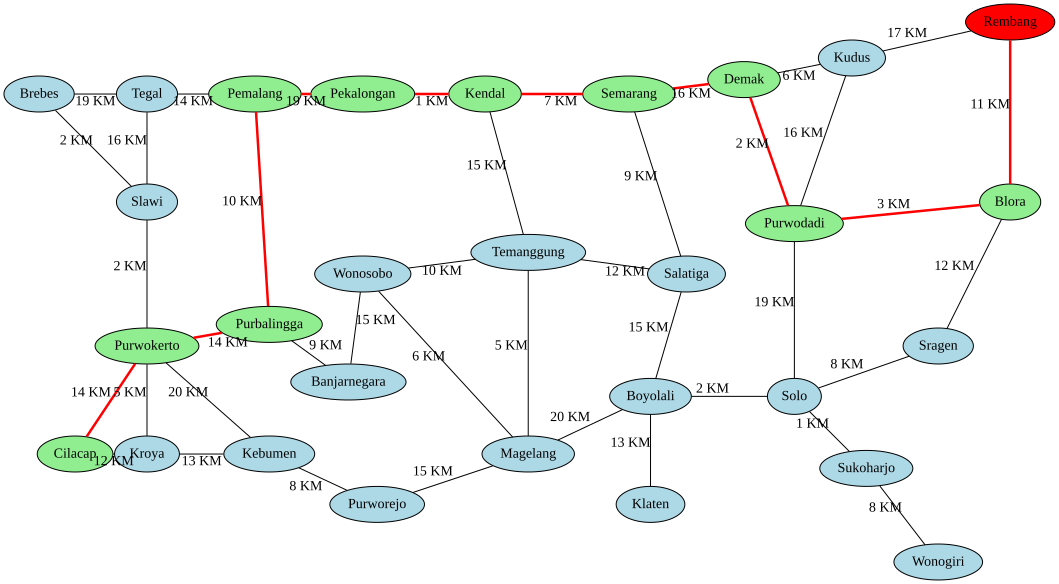

In [2]:
import collections
import heapq
import random
import graphviz
from IPython.display import display

# 1. Definisi Kelas WeightedGraph (Berdasarkan sumber [1, 5])
class WeightedGraph:
    def __init__(self, directed=False):
        self.graph = collections.defaultdict(list)
        self.nodes = set()
        self.directed = directed

    def add_edge(self, u, v, weight):
        self.graph[u].append((v, weight))
        self.nodes.add(u)
        self.nodes.add(v)
        if not self.directed:
            self.graph[v].append((u, weight))

    # Algoritma Dijkstra (Berdasarkan sumber [3, 6, 7])
    def dijkstra(self, start_node):
        distances = {node: float('infinity') for node in self.nodes}
        distances[start_node] = 0
        priority_queue = [(0, start_node)]
        previous_nodes = {}

        while priority_queue:
            current_distance, current_node = heapq.heappop(priority_queue)

            if current_distance > distances[current_node]:
                continue

            for neighbor, weight in self.graph[current_node]:
                distance = current_distance + weight
                if distance < distances[neighbor]:
                    distances[neighbor] = distance
                    previous_nodes[neighbor] = current_node
                    heapq.heappush(priority_queue, (distance, neighbor))
        
        return distances, previous_nodes

    # Fungsi mengambil rute (Berdasarkan sumber [8])
    def get_shortest_path(self, start_node, end_node, previous_nodes):
        path = collections.deque()
        current = end_node
        while current is not None:
            path.appendleft(current)
            current = previous_nodes.get(current)
            if current == start_node:
                path.appendleft(current)
                break
        return list(path)

# 2. Fungsi Visualisasi (Berdasarkan sumber [9-11])
def visualize_peta_final(graph_obj, highlight_path=None):
    dot = graphviz.Graph(comment="Peta Jateng 1-20KM", engine='neato')
    
    # Koordinat x,y manual agar sesuai gambar tugas
    positions = {
        'Brebes': '0,10!', 'Tegal': '1.5,10!', 'Slawi': '1.5,8.5!', 'Pemalang': '3,10!', 
        'Pekalongan': '4.5,10!', 'Kendal': '6.2,10!', 'Semarang': '8.2,10!', 
        'Demak': '9.8,10.2!', 'Kudus': '11.3,10.5!', 'Rembang': '13.5,11!',
        'Purwokerto': '1.5,6.5!', 'Cilacap': '0.5,5!', 'Kroya': '1.5,5!', 
        'Purbalingga': '3.2,6.8!', 'Banjarnegara': '4.3,6!', 'Kebumen': '3.2,5!',
        'Purworejo': '4.7,4.3!', 'Wonosobo': '4.5, 7.5!', 'Temanggung': '6.8, 7.8!', 
        'Salatiga': '9.0, 7.5!', 'Magelang': '6.8,5!', 'Boyolali': '8.5,5.8!',
        'Klaten': '8.5,4.3!', 'Solo': '10.5,5.8!', 'Sragen': '12.5, 6.5!', 
        'Blora': '13.5, 8.5!', 'Purwodadi': '10.5, 8.2!', 'Sukoharjo': '11.5, 4.8!', 
        'Wonogiri': '12.5, 3.5!'
    }

    for node, pos in positions.items():
        color = 'lightblue'
        if highlight_path and node in highlight_path:
            # Merah untuk start/finish, hijau untuk jalur diantaranya [10]
            color = 'red' if (node == highlight_path or node == highlight_path[-1]) else 'lightgreen'
        dot.node(node, node, shape='ellipse', style='filled', fillcolor=color, pos=pos)
        
    added_edges = set()
    for u, neighbors in graph_obj.graph.items():
        for v, weight in neighbors:
            if (v, u) not in added_edges:
                edge_color, penwidth = 'black', '1.0'
                if highlight_path:
                    for i in range(len(highlight_path)-1):
                        if (u == highlight_path[i] and v == highlight_path[i+1]) or \
                           (v == highlight_path[i] and u == highlight_path[i+1]):
                            edge_color, penwidth = 'red', '2.5' # Garis merah untuk rute terpendek [12]
                
                dot.edge(u, v, label=f"{weight} KM", color=edge_color, penwidth=penwidth)
                added_edges.add((u, v))
    return dot

# 3. Setup Data Peta
peta_jateng = WeightedGraph(directed=False)
random.seed(10) # Seed agar hasil jarak random konsisten saat dicoba

connections = [
    ('Brebes', 'Tegal'), ('Brebes', 'Slawi'), ('Tegal', 'Pemalang'), ('Tegal', 'Slawi'),
    ('Pemalang', 'Pekalongan'), ('Pekalongan', 'Kendal'), ('Kendal', 'Semarang'),
    ('Kendal', 'Temanggung'), ('Semarang', 'Demak'), ('Semarang', 'Salatiga'),
    ('Demak', 'Kudus'), ('Demak', 'Purwodadi'), ('Kudus', 'Rembang'), ('Kudus', 'Purwodadi'),
    ('Rembang', 'Blora'), ('Blora', 'Purwodadi'), ('Sragen', 'Solo'), ('Sragen', 'Blora'),
    ('Slawi', 'Purwokerto'), ('Purwokerto', 'Cilacap'), ('Purwokerto', 'Kroya'),
    ('Purwokerto', 'Kebumen'), ('Cilacap', 'Kroya'), ('Kroya', 'Kebumen'),
    ('Purbalingga', 'Purwokerto'), ('Purbalingga', 'Pemalang'), ('Purbalingga', 'Banjarnegara'),
    ('Banjarnegara', 'Wonosobo'), ('Wonosobo', 'Magelang'), ('Wonosobo', 'Temanggung'),
    ('Temanggung', 'Salatiga'), ('Temanggung', 'Magelang'), ('Salatiga', 'Boyolali'),
    ('Kebumen', 'Purworejo'), ('Purworejo', 'Magelang'), ('Magelang', 'Boyolali'),
    ('Boyolali', 'Klaten'), ('Boyolali', 'Solo'), ('Solo', 'Purwodadi'),
    ('Solo', 'Sukoharjo'), ('Sukoharjo', 'Wonogiri')
]

for u, v in connections:
    # REVISI: Range jarak 1 - 20 KM
    jarak = random.randint(1, 20)
    peta_jateng.add_edge(u, v, jarak)

# 4. Contoh Rute Baru: Cilacap ke Rembang
asal = 'Cilacap'
tujuan = 'Rembang'

distances, previous_nodes = peta_jateng.dijkstra(asal)
rute = peta_jateng.get_shortest_path(asal, tujuan, previous_nodes)

print(f"--- ANALISIS RUTE TERPENDEK ---")
print(f"Dari: {asal}")
print(f"Tujuan: {tujuan}")
print(f"Total Jarak: {distances[tujuan]} KM")
print(f"Rute yang dilewati: {' -> '.join(rute)}")

display(visualize_peta_final(peta_jateng, highlight_path=rute))